# 01 — Synthetic Data Foundation

**Section:** Evaluation layer (PROMETHEE II, CART baseline, statistical testing, GSEA)
**Purpose:** Everything downstream (CART, PROMETHEE II, Mann–Whitney/Wilcoxon) needs an
input schema to run against. Real DeepCCDS predictions and real GA/NSGA-II rule sets
aren't ready yet, so this notebook fabricates a stand-in dataset that mimics the shape
DeepCCDS actually produces, so:

1. You can build and test the rest of the evaluation pipeline right now, not later.
2. The saved schema (`tests/fixtures/synthetic/*.csv`) doubles as a spec for what to expect from
   teammates' branches — worth comparing against their real output columns once ready.
3. Because the "true" signal is known here (we generate it), you can sanity-check that
   your CART/PROMETHEE/GSEA code actually recovers it, which you can never fully verify
   on real data alone.

**What DeepCCDS actually predicts** (per Wu et al., the architecture this project builds
on): a single continuous value, `LN_IC50`, per cell-line/drug pair, from two interpretable
input blocks:
- Gene mutation status (binary, per driver gene)
- Pathway activity scores (continuous, per biological pathway, derived from gene expression via ssGSEA)

Those two blocks are what makes downstream rules ("IF TP53_mut = 1 AND MAPK_pathway > 0.6
THEN resistant") and GSEA pathway enrichment meaningful, so the synthetic features below
are built at that same level rather than as opaque embeddings.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

RNG_SEED = 42
rng = np.random.default_rng(RNG_SEED)

N_CELL_LINES = 300     # small relative to real GDSC (~866 lines) but enough for stats
N_DRIVER_GENES = 20    # subset standing in for COSMIC CGC driver genes
N_PATHWAYS = 38         # matches DeepCCDS's 38 pathway-activity features
N_CANCER_TYPES = 6      # needed later for the PROMETHEE "stability across subtypes" criterion

OUT_DIR = "../tests/fixtures/synthetic"  # test fixture, not a real pipeline artifact — kept out of artifacts/


## 1. Feature generation

Two interpretable feature blocks, matching DeepCCDS's inputs:
- `mutations`: binary matrix, driver gene mutation status per cell line
- `pathway_activity`: continuous matrix, pathway activity score per cell line

A `cancer_type` label is attached per cell line so the PROMETHEE II **stability** criterion
(variance in rule performance across tissue/cancer subtypes, Section 4.6.1) has something
to be computed over.


In [2]:
gene_names = [f"GENE_{i:02d}" for i in range(1, N_DRIVER_GENES + 1)]
pathway_names = [f"PATHWAY_{i:02d}" for i in range(1, N_PATHWAYS + 1)]
cancer_types = [f"CANCER_TYPE_{i}" for i in range(1, N_CANCER_TYPES + 1)]

cell_line_ids = [f"SYN_CL_{i:04d}" for i in range(1, N_CELL_LINES + 1)]
cell_line_cancer_type = rng.choice(cancer_types, size=N_CELL_LINES)

# Mutation rates vary by gene (some driver genes are just rarer than others in real data)
mutation_rates = rng.uniform(0.05, 0.45, size=N_DRIVER_GENES)
mutations = rng.binomial(1, mutation_rates, size=(N_CELL_LINES, N_DRIVER_GENES))
mutations_df = pd.DataFrame(mutations, columns=gene_names, index=cell_line_ids)

# Pathway activity scores: roughly standard-normal per pathway, independent for now.
# (Real pathway activities from ssGSEA correlate with each other and with mutation status;
#  that correlation structure isn't reproduced here, since it isn't needed for testing the
#  evaluation code — flag this as a known simplification, not a hidden assumption.)
pathway_activity = rng.normal(loc=0.0, scale=1.0, size=(N_CELL_LINES, N_PATHWAYS))
pathway_df = pd.DataFrame(pathway_activity, columns=pathway_names, index=cell_line_ids)

features_df = pd.concat([mutations_df, pathway_df], axis=1)
features_df.insert(0, "cancer_type", cell_line_cancer_type)
features_df.index.name = "cell_line_id"
features_df.head()


,cancer_type,GENE_01,GENE_02,GENE_03,GENE_04,GENE_05,GENE_06,GENE_07,GENE_08,GENE_09,...,PATHWAY_29,PATHWAY_30,PATHWAY_31,PATHWAY_32,PATHWAY_33,PATHWAY_34,PATHWAY_35,PATHWAY_36,PATHWAY_37,PATHWAY_38
cell_line_id,,,,,,,,,,,,,,,,,,,,,
SYN_CL_0001,CANCER_TYPE_1,0,0,0,1,0,0,0,1,1,...,-1.197054,1.989360,-0.096382,0.644514,-0.536869,-1.051928,-0.233881,1.101193,-0.520732,-0.870532
SYN_CL_0002,CANCER_TYPE_5,1,0,0,1,0,0,0,1,0,...,0.218819,-1.289335,-0.335039,-0.518845,0.464450,1.017022,0.991067,-0.842812,0.998468,-0.044085
SYN_CL_0003,CANCER_TYPE_4,1,0,0,1,0,1,0,0,1,...,1.285997,-0.210830,-0.141779,0.170046,0.891898,-1.470216,0.736056,-0.020496,-1.058637,-2.084606
SYN_CL_0004,CANCER_TYPE_3,0,0,1,0,1,1,0,1,0,...,0.669823,-2.666917,-0.066789,2.083211,1.326129,-1.847090,-0.313426,-1.201519,1.711102,0.244278
SYN_CL_0005,CANCER_TYPE_3,1,1,0,0,0,1,0,0,0,...,-0.063005,-1.630658,1.410763,-0.774352,1.026072,-0.621377,-0.625505,1.213123,0.993885,0.208666


## 2. A known ground-truth signal

Pick a small number of genes/pathways to actually drive drug response, and make everything
else noise. This is the part real data never gives you: knowing in advance which features
*should* show up in a good rule set. Use this later to check whether CART/GA/NSGA-II rules
recover `TRUE_SIGNAL_GENES` / `TRUE_SIGNAL_PATHWAYS` more than chance, and whether SAM-style
smoother predictions recover them more reliably than noisy/overfit ones.


In [3]:
TRUE_SIGNAL_GENES = rng.choice(gene_names, size=4, replace=False).tolist()
TRUE_SIGNAL_PATHWAYS = rng.choice(pathway_names, size=3, replace=False).tolist()

gene_coefs = {g: rng.uniform(0.8, 1.6) * rng.choice([-1, 1]) for g in TRUE_SIGNAL_GENES}
pathway_coefs = {p: rng.uniform(0.5, 1.2) * rng.choice([-1, 1]) for p in TRUE_SIGNAL_PATHWAYS}

print("Signal genes:    ", gene_coefs)
print("Signal pathways: ", pathway_coefs)

true_signal = np.zeros(N_CELL_LINES)
for g, c in gene_coefs.items():
    true_signal += c * features_df[g].values
for p, c in pathway_coefs.items():
    true_signal += c * features_df[p].values

# GDSC LN_IC50 values typically sit roughly in [-8, 8]; centre and scale to land there.
true_signal = 2.0 * (true_signal - true_signal.mean()) / true_signal.std()
true_ln_ic50 = true_signal  # this is the noise-free "ground truth" a perfect model would predict


Signal genes:     {'GENE_11': np.float64(1.5245732668264842), 'GENE_12': np.float64(-1.2831015452046273), 'GENE_06': np.float64(0.8812153486871951), 'GENE_17': np.float64(-0.8571748534404373)}
Signal pathways:  {'PATHWAY_30': np.float64(-1.1490009722615384), 'PATHWAY_19': np.float64(-0.83762833894204), 'PATHWAY_25': np.float64(0.803150655356085)}


## 3. Simulating two model conditions (baseline vs SAM)

Real predictions will come from Angelique's and Bahiya's branches. Until then, fabricate
predictions with the *qualitative* difference the proposal's hypothesis is built on
(Section 4.8.1): the SAM-regularised model should show a smaller **generalisation gap**
(train vs held-out error) than the unregularised baseline, while both still centre on the
same underlying signal.

This is simulated directly (not by training a real network), by giving:
- the **baseline** a small train-set noise but a much larger held-out noise (it memorised training quirks)
- **SAM** a similar train-set noise but a held-out noise much closer to its train-set noise (it generalised)


In [4]:
train_idx, test_idx = train_test_split(
    np.arange(N_CELL_LINES), test_size=0.2, random_state=RNG_SEED
)
split = np.array(["train"] * N_CELL_LINES)
split[test_idx] = "test"

def simulate_predictions(train_noise_sd, test_noise_sd):
    preds = true_ln_ic50.copy()
    noise = np.empty(N_CELL_LINES)
    noise[train_idx] = rng.normal(0, train_noise_sd, size=len(train_idx))
    noise[test_idx] = rng.normal(0, test_noise_sd, size=len(test_idx))
    return preds + noise

baseline_preds = simulate_predictions(train_noise_sd=0.35, test_noise_sd=1.60)  # large gap
sam_preds = simulate_predictions(train_noise_sd=0.45, test_noise_sd=0.65)       # small gap

def mse(a, b):
    return float(np.mean((a - b) ** 2))

gap_baseline = mse(baseline_preds[test_idx], true_ln_ic50[test_idx]) - mse(baseline_preds[train_idx], true_ln_ic50[train_idx])
gap_sam = mse(sam_preds[test_idx], true_ln_ic50[test_idx]) - mse(sam_preds[train_idx], true_ln_ic50[train_idx])

print(f"Baseline generalisation gap (test MSE - train MSE): {gap_baseline:.3f}")
print(f"SAM      generalisation gap (test MSE - train MSE): {gap_sam:.3f}")
assert gap_sam < gap_baseline, "Synthetic SAM condition should show the smaller gap by construction"


Baseline generalisation gap (test MSE - train MSE): 1.792
SAM      generalisation gap (test MSE - train MSE): 0.169


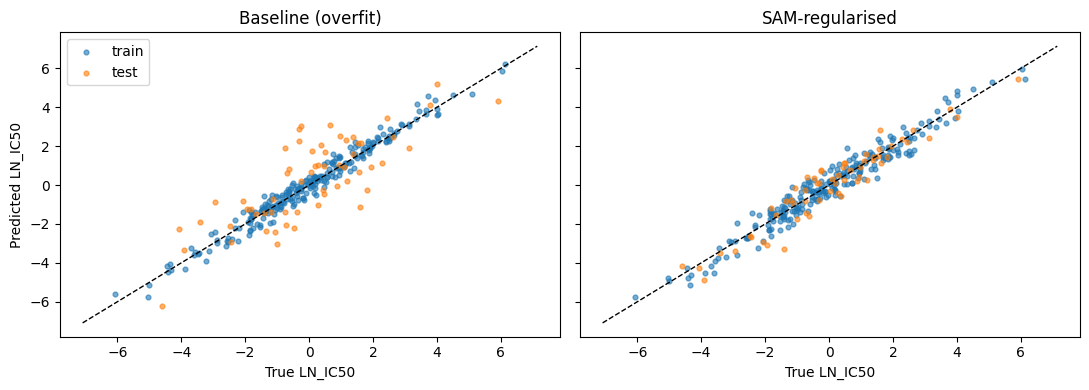

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, preds, title in zip(ax, [baseline_preds, sam_preds], ["Baseline (overfit)", "SAM-regularised"]):
    a.scatter(true_ln_ic50[train_idx], preds[train_idx], s=12, alpha=0.6, label="train")
    a.scatter(true_ln_ic50[test_idx], preds[test_idx], s=12, alpha=0.6, label="test")
    lims = [true_ln_ic50.min() - 1, true_ln_ic50.max() + 1]
    a.plot(lims, lims, "k--", linewidth=1)
    a.set_title(title)
    a.set_xlabel("True LN_IC50")
ax[0].set_ylabel("Predicted LN_IC50")
ax[0].legend()
plt.tight_layout()
plt.show()


## 4. Discretisation: continuous LN_IC50 → sensitive/resistant

Per the proposal's fix (LN_IC50 is a continuous regression target; a discretisation step
must happen before macro-F1 and rule extraction). Threshold uses the **median of the true
signal** as a simple, defensible cutpoint for synthetic purposes — swap for whatever
threshold convention the team lands on for real GDSC values (e.g. drug-specific or GDSC's
own published cutoffs) once that's decided; don't treat this median-split as the final rule.


In [6]:
THRESHOLD = float(np.median(true_ln_ic50))
print(f"Discretisation threshold (median of true LN_IC50): {THRESHOLD:.3f}")

def discretise(values, threshold=THRESHOLD):
    # lower LN_IC50 = more sensitive to the drug (per GDSC convention)
    return np.where(values <= threshold, "sensitive", "resistant")

labels_df = pd.DataFrame({
    "cell_line_id": cell_line_ids,
    "split": split,
    "cancer_type": cell_line_cancer_type,
    "true_ln_ic50": true_ln_ic50,
    "baseline_pred_ln_ic50": baseline_preds,
    "sam_pred_ln_ic50": sam_preds,
    "true_class": discretise(true_ln_ic50),
    "baseline_pred_class": discretise(baseline_preds),
    "sam_pred_class": discretise(sam_preds),
}).set_index("cell_line_id")

print(labels_df["true_class"].value_counts())
labels_df.head()


Discretisation threshold (median of true LN_IC50): -0.019
true_class
sensitive    150
resistant    150
Name: count, dtype: int64


,split,cancer_type,true_ln_ic50,baseline_pred_ln_ic50,sam_pred_ln_ic50,true_class,baseline_pred_class,sam_pred_class
cell_line_id,,,,,,,,
SYN_CL_0001,train,CANCER_TYPE_1,-1.385539,-1.230942,-1.157837,sensitive,sensitive,sensitive
SYN_CL_0002,train,CANCER_TYPE_5,2.231962,2.999060,2.129065,resistant,resistant,resistant
SYN_CL_0003,train,CANCER_TYPE_4,2.005836,2.236233,1.808526,resistant,resistant,resistant
SYN_CL_0004,train,CANCER_TYPE_3,5.110130,4.682037,5.304260,resistant,resistant,resistant
SYN_CL_0005,train,CANCER_TYPE_3,3.939138,4.382661,3.437482,resistant,resistant,resistant


## 5. Save outputs

Two files land in `tests/fixtures/synthetic/`:
- `synthetic_features.csv` — mutation status + pathway activity + cancer_type, per cell line
- `synthetic_labels.csv` — true/baseline/SAM LN_IC50 and their discretised classes, per cell line, with train/test split flag

**Schema note for the team:** once real DeepCCDS output exists (Angelique's/Bahiya's
branches), it should be reshapeable into this same `labels_df` structure (one row per
cell-line×drug pair, a continuous prediction column, a discretised class column) so this
evaluation code doesn't need to change, just point at real files instead of synthetic ones.


In [7]:
import os
os.makedirs(OUT_DIR, exist_ok=True)
features_df.to_csv(f"{OUT_DIR}/synthetic_features.csv")
labels_df.to_csv(f"{OUT_DIR}/synthetic_labels.csv")

# Small metadata file recording what the "ground truth" signal was, for sanity-checking
# CART/GA/NSGA-II rules later against what actually drove the synthetic response.
meta = {
    "true_signal_genes": gene_coefs,
    "true_signal_pathways": pathway_coefs,
    "discretisation_threshold": THRESHOLD,
    "rng_seed": RNG_SEED,
}
import json
with open(f"{OUT_DIR}/synthetic_ground_truth_meta.json", "w") as f:
    json.dump(meta, f, indent=2)

print("Saved:")
print(f"  {OUT_DIR}/synthetic_features.csv       {features_df.shape}")
print(f"  {OUT_DIR}/synthetic_labels.csv          {labels_df.shape}")
print(f"  {OUT_DIR}/synthetic_ground_truth_meta.json")


Saved:
  ../tests/fixtures/synthetic/synthetic_features.csv       (300, 59)
  ../tests/fixtures/synthetic/synthetic_labels.csv          (300, 8)
  ../tests/fixtures/synthetic/synthetic_ground_truth_meta.json


## Next up

With this schema in place, the natural next notebooks are:
1. **CART baseline** — fit on `baseline_pred_class` and `sam_pred_class` separately, extract
   path rules, and check whether they recover `TRUE_SIGNAL_GENES`/`TRUE_SIGNAL_PATHWAYS`.
2. **PROMETHEE II ranking** — needs fabricated GA/NSGA-II-style rule sets (with fidelity,
   comprehensibility, stability scores) alongside the CART rules from (1), combined into a
   single ranking run per Section 4.6.1.
3. **Statistical testing** — Mann–Whitney U across the GA/NSGA-II/CART groups once (2) exists.

Say the word when you want the next one built.


## 6. Session update — decisions locked in (recorded here for continuity)

Three decisions from tonight's coordination session, kept here so this notebook stays
a source of truth as the team's plan solidifies:

1. **Feature space confirmed**: pathway activity (continuous) + mutation status (binary) —
   the features DeepCCDS itself trains on. This notebook already used that representation,
   so no change needed above.
2. **Per-drug rule extraction confirmed**: rules are extracted separately for each selected
   drug, holding the drug fixed, rather than mixing drugs into one global rule set with
   fingerprint bits as conditions. This notebook was already implicitly single-drug — see
   Section 7 below for what changes once this is made explicit across multiple drugs.
3. **Degenerate-rule fix confirmed**: both GA and NSGA-II rule pools get filtered by a
   minimum coverage threshold *before* they reach PROMETHEE II, rather than changing
   NSGA-II's objectives or PROMETHEE's criteria. Starting threshold: 2% (0.02), matching
   Sakhile's tested value — subject to the team confirming this number stays fixed across
   both extractors.


## 7. Demonstrating the per-drug loop

The real pipeline won't run once — it runs once *per selected drug* (see Part 1 of tonight's
discussion for how "well-resourced" drugs get chosen). The cell below refactors Sections 1–4
into a reusable function and runs it for three placeholder drugs, to prove out the loop
structure and the per-drug file layout before real drug names/counts exist.


In [8]:
def generate_synthetic_drug_dataset(drug_id, rng_seed):
    """Repeats Sections 1-4 for a single drug, returning (features_df, labels_df, meta).
    Cell-line features (mutation status, pathway activity) are shared across drugs in
    reality -- only the response signal and predictions differ per drug -- so only the
    signal-generation and prediction steps are re-randomised per drug_id here.
    """
    local_rng = np.random.default_rng(rng_seed)

    # Reuse the same cell-line features generated in Section 1 (shared across drugs)
    signal_genes = local_rng.choice(gene_names, size=4, replace=False).tolist()
    signal_pathways = local_rng.choice(pathway_names, size=3, replace=False).tolist()
    gene_coefs_local = {g: local_rng.uniform(0.8, 1.6) * local_rng.choice([-1, 1]) for g in signal_genes}
    pathway_coefs_local = {p: local_rng.uniform(0.5, 1.2) * local_rng.choice([-1, 1]) for p in signal_pathways}

    signal = np.zeros(N_CELL_LINES)
    for g, c in gene_coefs_local.items():
        signal += c * features_df[g].values
    for p, c in pathway_coefs_local.items():
        signal += c * features_df[p].values
    signal = 2.0 * (signal - signal.mean()) / signal.std()

    tr_idx, te_idx = train_test_split(np.arange(N_CELL_LINES), test_size=0.2, random_state=rng_seed)
    split_local = np.array(["train"] * N_CELL_LINES)
    split_local[te_idx] = "test"

    def sim_preds(train_sd, test_sd):
        preds = signal.copy()
        noise = np.empty(N_CELL_LINES)
        noise[tr_idx] = local_rng.normal(0, train_sd, size=len(tr_idx))
        noise[te_idx] = local_rng.normal(0, test_sd, size=len(te_idx))
        return preds + noise

    baseline_p = sim_preds(0.35, 1.60)
    sam_p = sim_preds(0.45, 0.65)
    thresh = float(np.median(signal))

    def disc(v):
        return np.where(v <= thresh, "sensitive", "resistant")

    labels = pd.DataFrame({
        "cell_line_id": cell_line_ids, "drug_id": drug_id, "split": split_local,
        "true_ln_ic50": signal, "baseline_pred_ln_ic50": baseline_p, "sam_pred_ln_ic50": sam_p,
        "true_class": disc(signal), "baseline_pred_class": disc(baseline_p), "sam_pred_class": disc(sam_p),
    }).set_index("cell_line_id")

    meta = {"drug_id": drug_id, "true_signal_genes": gene_coefs_local,
            "true_signal_pathways": pathway_coefs_local, "discretisation_threshold": thresh}
    return labels, meta


PLACEHOLDER_DRUGS = ["SYN_DRUG_A", "SYN_DRUG_B", "SYN_DRUG_C"]
per_drug_dir = f"{OUT_DIR}/per_drug"
os.makedirs(per_drug_dir, exist_ok=True)

for i, drug_id in enumerate(PLACEHOLDER_DRUGS):
    drug_labels, drug_meta = generate_synthetic_drug_dataset(drug_id, rng_seed=RNG_SEED + i + 1)
    drug_dir = f"{per_drug_dir}/{drug_id}"
    os.makedirs(drug_dir, exist_ok=True)
    drug_labels.to_csv(f"{drug_dir}/labels.csv")
    with open(f"{drug_dir}/meta.json", "w") as f:
        json.dump(drug_meta, f, indent=2)
    print(f"{drug_id}: {drug_labels['true_class'].value_counts().to_dict()}  -> {drug_dir}/")

print("\nCell-line features (tests/fixtures/synthetic/synthetic_features.csv) are shared across all drugs;")
print("only tests/fixtures/synthetic/per_drug/{drug_id}/labels.csv changes per drug.")


SYN_DRUG_A: {'sensitive': 150, 'resistant': 150}  -> ../tests/fixtures/synthetic/per_drug/SYN_DRUG_A/
SYN_DRUG_B: {'sensitive': 150, 'resistant': 150}  -> ../tests/fixtures/synthetic/per_drug/SYN_DRUG_B/
SYN_DRUG_C: {'sensitive': 150, 'resistant': 150}  -> ../tests/fixtures/synthetic/per_drug/SYN_DRUG_C/

Cell-line features (tests/fixtures/synthetic/synthetic_features.csv) are shared across all drugs;
only tests/fixtures/synthetic/per_drug/{drug_id}/labels.csv changes per drug.


**Real-world equivalent of this loop**: once the drug shortlist is confirmed (Part 1 of
tonight's discussion — "well-resourced" drugs by tested-cell-line count), CART/GA/NSGA-II
each run once per drug in this list, producing one rule pool per drug per model condition.
PROMETHEE II then runs as a **separate combined ranking per drug** (baseline + SAM + CART
rules for that one drug, ranked together) — not one ranking across all drugs at once, since
net outranking flows are only comparable within a single PROMETHEE execution (Section 4.6.1).
